In [2]:
import pandas as pd
import numpy as np
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
columns = [
    "lp", "v", "GTT", "GTn", "GGn", "Ts", "Tp", "T48", "T1", "T2","P48", "P1", "P2", "Pexh", "TIC", "mf",
    "kMc", "kMt"]

df = pd.read_csv("./UCI CBM Dataset/data.txt", sep=r"\s+", header = None, names = columns)

print(df.head())
#print(df.shape)


      lp     v        GTT       GTn       GGn       Ts       Tp      T48  \
0  1.138   3.0    289.964  1349.489  6677.380    7.584    7.584  464.006   
1  2.088   6.0   6960.180  1376.166  6828.469   28.204   28.204  635.401   
2  3.144   9.0   8379.229  1386.757  7111.811   60.358   60.358  606.002   
3  4.161  12.0  14724.395  1547.465  7792.630  113.774  113.774  661.471   
4  5.140  15.0  21636.432  1924.313  8494.777  175.306  175.306  731.494   

      T1       T2    P48     P1      P2   Pexh     TIC     mf   kMc    kMt  
0  288.0  550.563  1.096  0.998   5.947  1.019   7.137  0.082  0.95  0.975  
1  288.0  581.658  1.331  0.998   7.282  1.019  10.655  0.287  0.95  0.975  
2  288.0  587.587  1.389  0.998   7.574  1.020  13.086  0.259  0.95  0.975  
3  288.0  613.851  1.658  0.998   9.007  1.022  18.109  0.358  0.95  0.975  
4  288.0  645.642  2.078  0.998  11.197  1.026  26.373  0.522  0.95  0.975  


In [ ]:
data = np.loadtxt("./UCI CBM Dataset/data.txt")
data

array([[1.1380000e+00, 3.0000000e+00, 2.8996400e+02, ..., 8.2000000e-02,
        9.5000000e-01, 9.7500000e-01],
       [2.0880000e+00, 6.0000000e+00, 6.9601800e+03, ..., 2.8700000e-01,
        9.5000000e-01, 9.7500000e-01],
       [3.1440000e+00, 9.0000000e+00, 8.3792290e+03, ..., 2.5900000e-01,
        9.5000000e-01, 9.7500000e-01],
       ...,
       [7.1480000e+00, 2.1000000e+01, 3.9003867e+04, ..., 8.3400000e-01,
        1.0000000e+00, 1.0000000e+00],
       [8.2060000e+00, 2.4000000e+01, 5.0992579e+04, ..., 1.1490000e+00,
        1.0000000e+00, 1.0000000e+00],
       [9.3000000e+00, 2.7000000e+01, 7.2775130e+04, ..., 1.7040000e+00,
        1.0000000e+00, 1.0000000e+00]])

In [24]:
data[:-2]

array([[1.1380000e+00, 3.0000000e+00, 2.8996400e+02, ..., 8.2000000e-02,
        9.5000000e-01, 9.7500000e-01],
       [2.0880000e+00, 6.0000000e+00, 6.9601800e+03, ..., 2.8700000e-01,
        9.5000000e-01, 9.7500000e-01],
       [3.1440000e+00, 9.0000000e+00, 8.3792290e+03, ..., 2.5900000e-01,
        9.5000000e-01, 9.7500000e-01],
       ...,
       [5.1400000e+00, 1.5000000e+01, 2.1624934e+04, ..., 4.7100000e-01,
        1.0000000e+00, 1.0000000e+00],
       [6.1750000e+00, 1.8000000e+01, 2.9763213e+04, ..., 6.4700000e-01,
        1.0000000e+00, 1.0000000e+00],
       [7.1480000e+00, 2.1000000e+01, 3.9003867e+04, ..., 8.3400000e-01,
        1.0000000e+00, 1.0000000e+00]])

Each row corresponds to a snapshot of a ship’s propulsion system under certain operating conditions.
models how engine components degrade over time under different conditions

Dataset structure:
- Samples: ~11,934
- Input features: 16
- Targets (labels): 2 continuous variables

Targets:
- GT Compressor Decay State Coefficient
- GT Turbine Decay State Coefficient
These represent health/degradation levels of the gas turbine components.

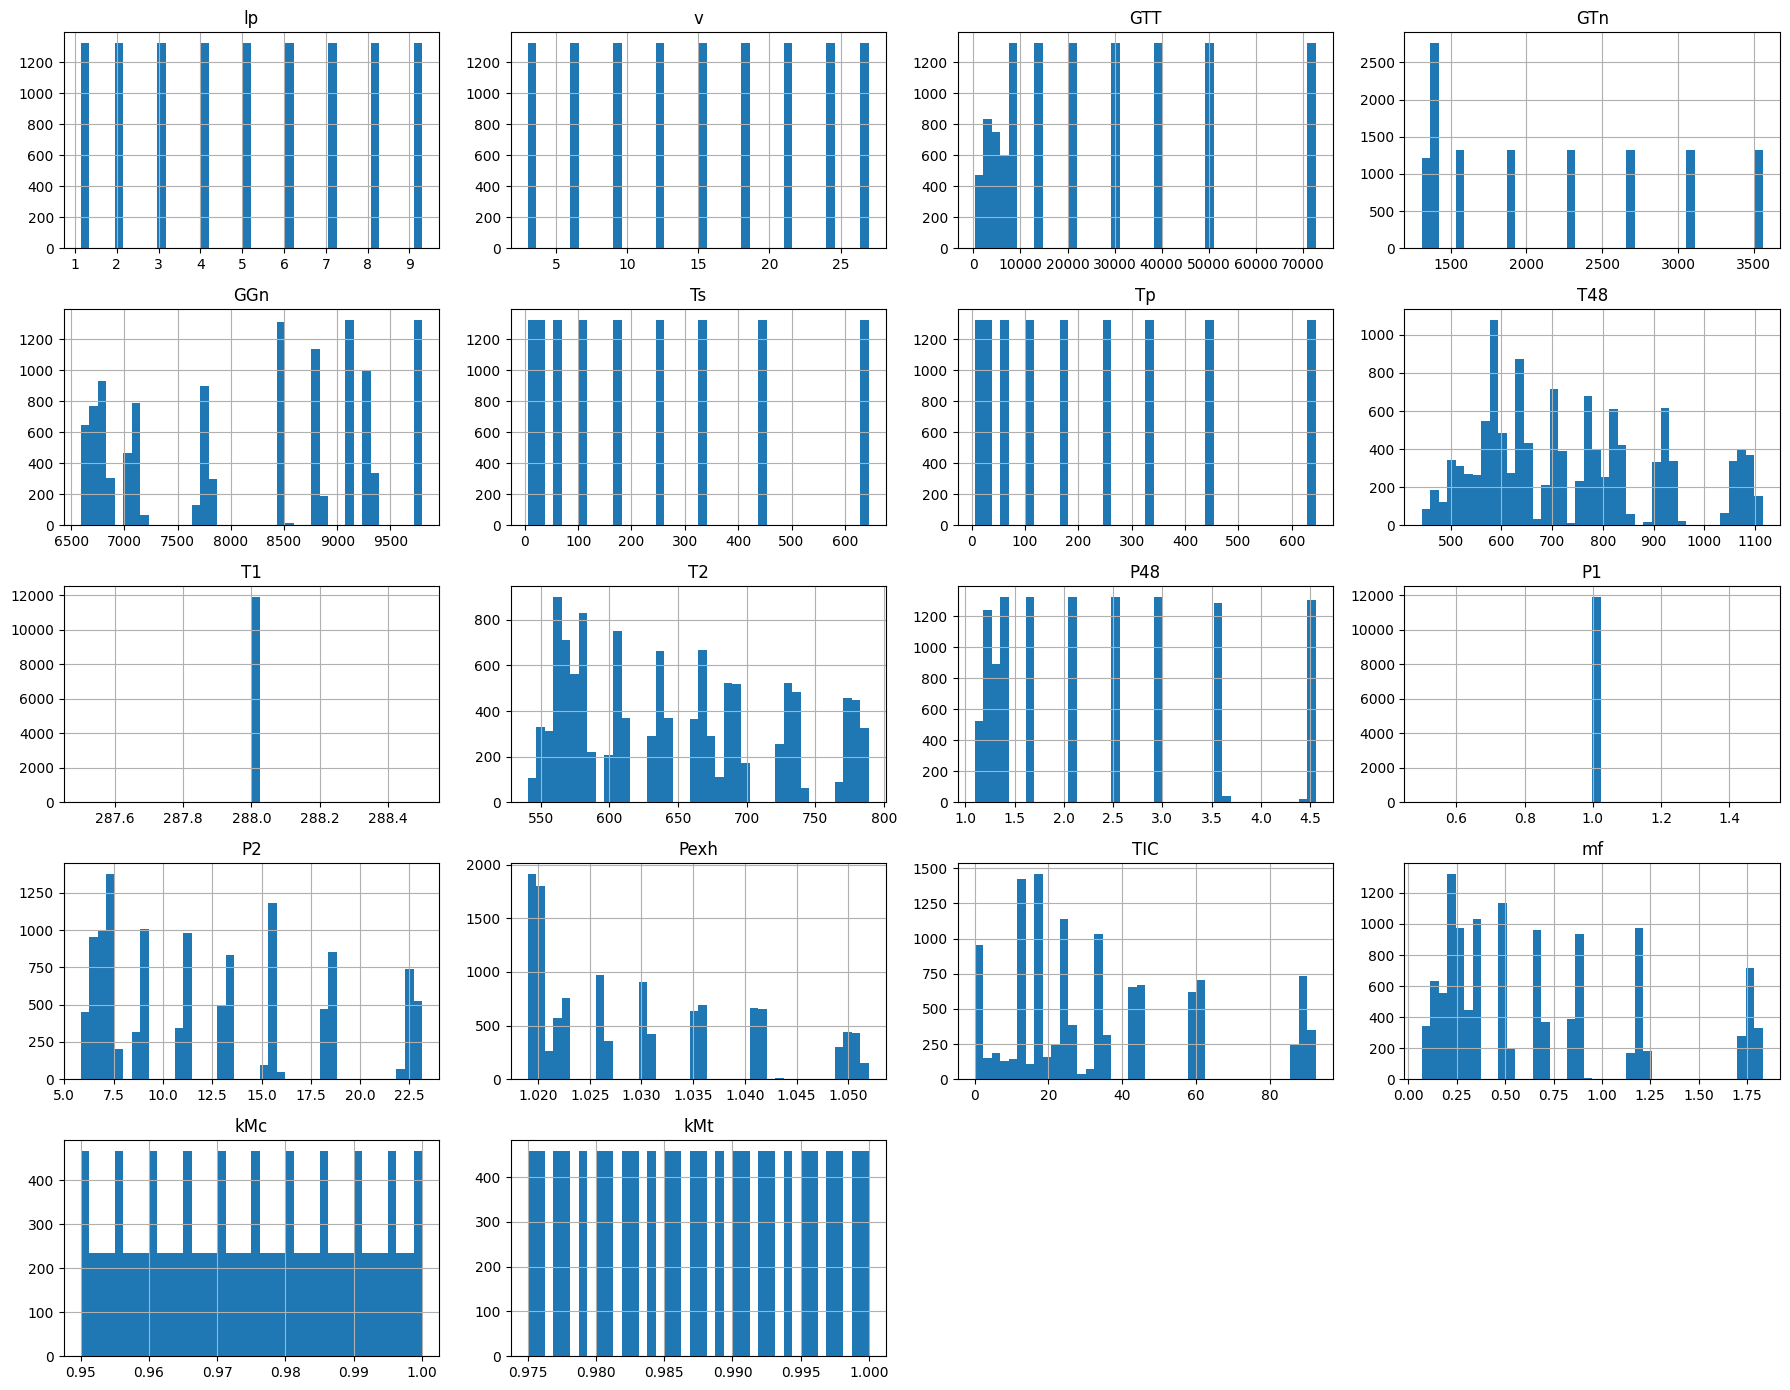

In [ ]:
df.hist(figsize = (18, 14), bins = 40)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="v", y="mf", alpha=0.3)
plt.title("Ship Speed vs Fuel Flow")
plt.show()


NASA Dataset

In [ ]:
cols = (
    ["unit", "time", "os1", "os2", "os3"] +
    [f"s{i}" for i in range(1, 22)]  # sensors s1–s21
)

def load_fd(fd):
    train = pd.read_csv(f"./CMAPSSData/train_FD{fd}.txt", sep=r"\s+", header=None, names=cols)
    test  = pd.read_csv(f"./CMAPSSData/test_FD{fd}.txt",  sep=r"\s+", header=None, names=cols)
    rul   = pd.read_csv(f"./CMAPSSData/RUL_FD{fd}.txt",   sep=r"\s+", header=None, names=["RUL"])
    return train, test, rul

train_fd1, test_fd1, rul_fd1 = load_fd("001")

In [13]:
def add_train_rul(df):
    max_time = df.groupby("unit")["time"].max()
    df = df.merge(max_time.rename("max_time"), on="unit")
    df["RUL"] = df["max_time"] - df["time"]
    return df.drop(columns=["max_time"])

train_fd1 = add_train_rul(train_fd1)


In [14]:
def add_test_rul(test, rul):
    last_cycles = test.groupby("unit")["time"].max().reset_index()
    last_cycles["RUL"] = rul["RUL"]
    return test.merge(last_cycles[["unit", "RUL"]], on="unit")

test_fd1 = add_test_rul(test_fd1, rul_fd1)


In [16]:
train_fd1.head(5)

,unit,time,os1,os2,os3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [17]:
test_fd1.head(5)

,unit,time,os1,os2,os3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,112
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,112
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,112
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,112
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,112


Sensor Distributions

Each engine (unit) runs through a sequence of cycles:

It starts healthy.
It gradually degrades.
In the training set, it runs all the way to failure.
In the test set, it stops before failure.


So the Remaining Useful Life (RUL) is:


How many cycles remain before the engine fails, starting from the last cycle in the test trajectory.


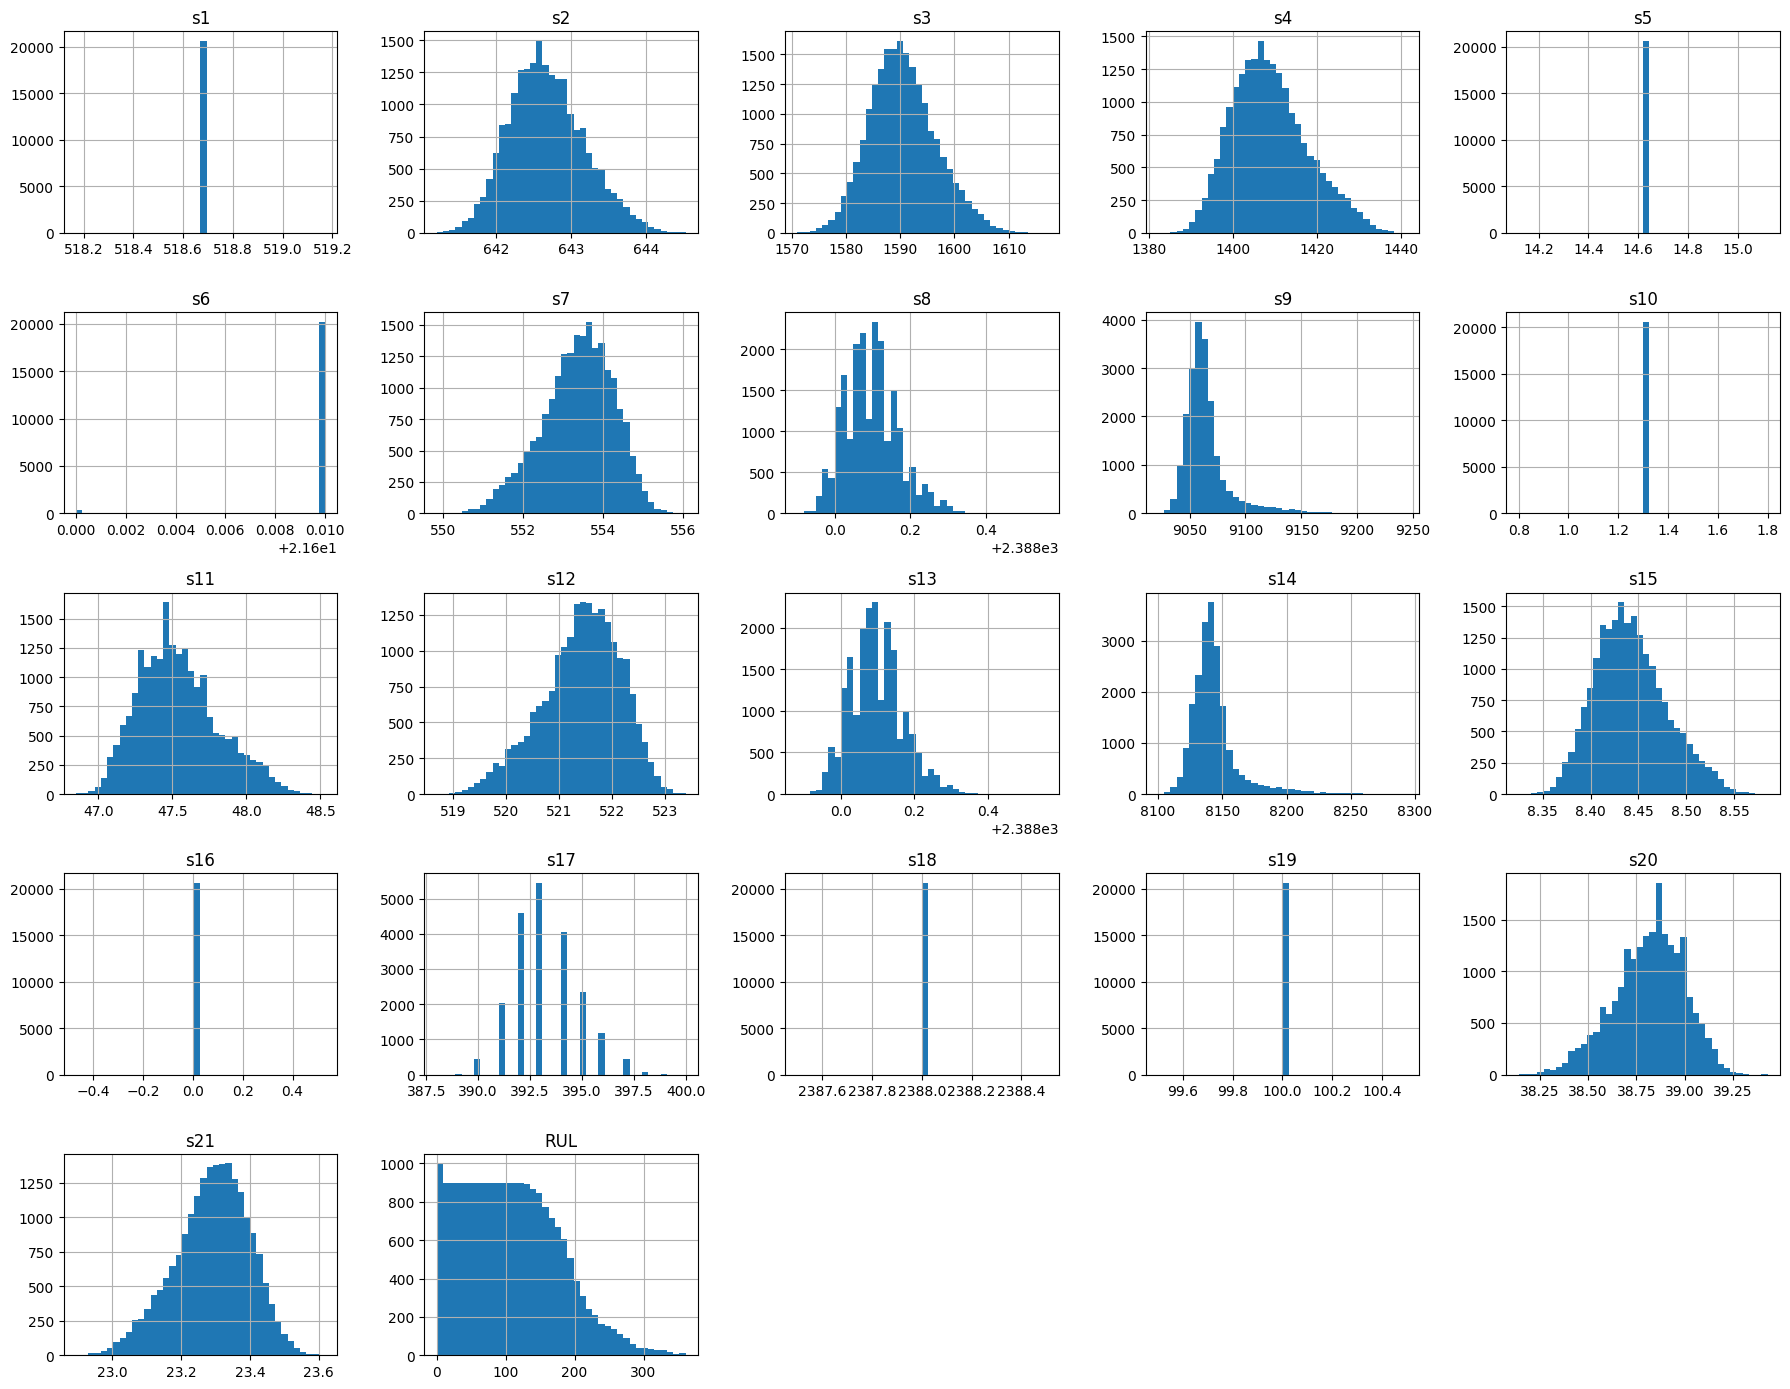

In [ ]:
train_fd1.iloc[:, 5:].hist(figsize = (18, 14), bins = 40)
plt.tight_layout()
plt.show()


In [143]:
rul_1_gt = pd.read_csv('./CMAPSSData/RUL_FD001.txt', header = None)
rul_1_gt.rename(columns={0: "RUL_1gt"}, inplace = True)

column_name_dict = { 0: "engine_id", 1: "cycle", 2: "op_set_1", 3: "op_set_2", 4: "op_set_3", 5:"sensor_1", 6: "sensor_2",
                   7: "sensor_3", 8: "sensor_4", 9: "sensor_5", 10: "sensor_6", 11: "sensor_7", 12: "sensor_8", 13: "sensor_9",
                  14: "sensor_10", 15: "sensor_11", 16: "sensor_12", 17: "sensor_13", 18: "sensor_14", 19: "sensor_15", 20: "sensor_16",
                  21: "sensor_17", 22: "sensor_18", 23: "sensor_19", 24: "sensor_20", 25: "sensor_21", 26: "sensor_22", 27: "sensor_23"}

test_1 = pd.read_csv('./CMAPSSData/test_FD001.txt', header = None, sep = ' ')
test_1.rename(columns = column_name_dict, inplace = True)

train_1 = pd.read_csv('./CMAPSSData/train_FD001.txt', header = None, sep = ' ')
train_1.rename(columns = column_name_dict, inplace = True)

In [144]:
train_1

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_22,sensor_23
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,NaN,NaN
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,NaN,NaN
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,NaN,NaN
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,NaN,NaN
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,NaN,NaN
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,NaN,NaN
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,NaN,NaN
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,NaN,NaN


In [145]:
train_1.drop(columns = ["sensor_22", "sensor_23"], inplace = True)
test_1.drop(columns = ["sensor_22", "sensor_23"], inplace = True)

In [146]:
train_1.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


In [147]:
rul_1 = pd.DataFrame(train_1.groupby('engine_id')['cycle'].max()).reset_index()
rul_1.columns = ['engine_id', 'max']

rul_train_1 = train_1.merge(rul_1, on=['engine_id'], how='left')
rul_train_1['RUL'] = rul_train_1['max'] - rul_train_1['cycle']
rul_train_1.drop(['max'], axis=1, inplace = True)

In [148]:
rul_1_gt["engine_id"]=rul_1_gt.index + 1

max_1 = pd.DataFrame(test_1.groupby('engine_id')['cycle'].max()).reset_index()
max_1.columns = ['engine_id', 'max']
max_test_1 = test_1.merge(max_1, on=['engine_id'], how='left')
rul_test_1 = max_test_1.merge(rul_1_gt, on=['engine_id'], how='left')

rul_test_1['RUL'] = rul_test_1['max'] - rul_test_1['cycle'] + rul_test_1["RUL_1gt"] 
rul_test_1.drop(['max', 'RUL_1gt'], axis=1, inplace=True)

In [149]:
rul_train_1.groupby('engine_id')['cycle'].describe()

,count,mean,std,min,25%,50%,75%,max
engine_id,,,,,,,,
1,192.0,96.5,55.569776,1.0,48.75,96.5,144.25,192.0
2,287.0,144.0,82.993976,1.0,72.50,144.0,215.50,287.0
3,179.0,90.0,51.816986,1.0,45.50,90.0,134.50,179.0
4,189.0,95.0,54.703748,1.0,48.00,95.0,142.00,189.0
5,269.0,135.0,77.797815,1.0,68.00,135.0,202.00,269.0
...,...,...,...,...,...,...,...,...
96,336.0,168.5,97.139076,1.0,84.75,168.5,252.25,336.0
97,202.0,101.5,58.456537,1.0,51.25,101.5,151.75,202.0
98,156.0,78.5,45.177428,1.0,39.75,78.5,117.25,156.0


In [150]:
rul_train_1.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op_set_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_set_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_set_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,1.776400e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [137]:
deleted_1 = ["op_set_3", "sensor_18", "sensor_19"]

rul_train_1.drop(columns = deleted_1, inplace = True)
rul_test_1.drop(columns = deleted_1, inplace = True)

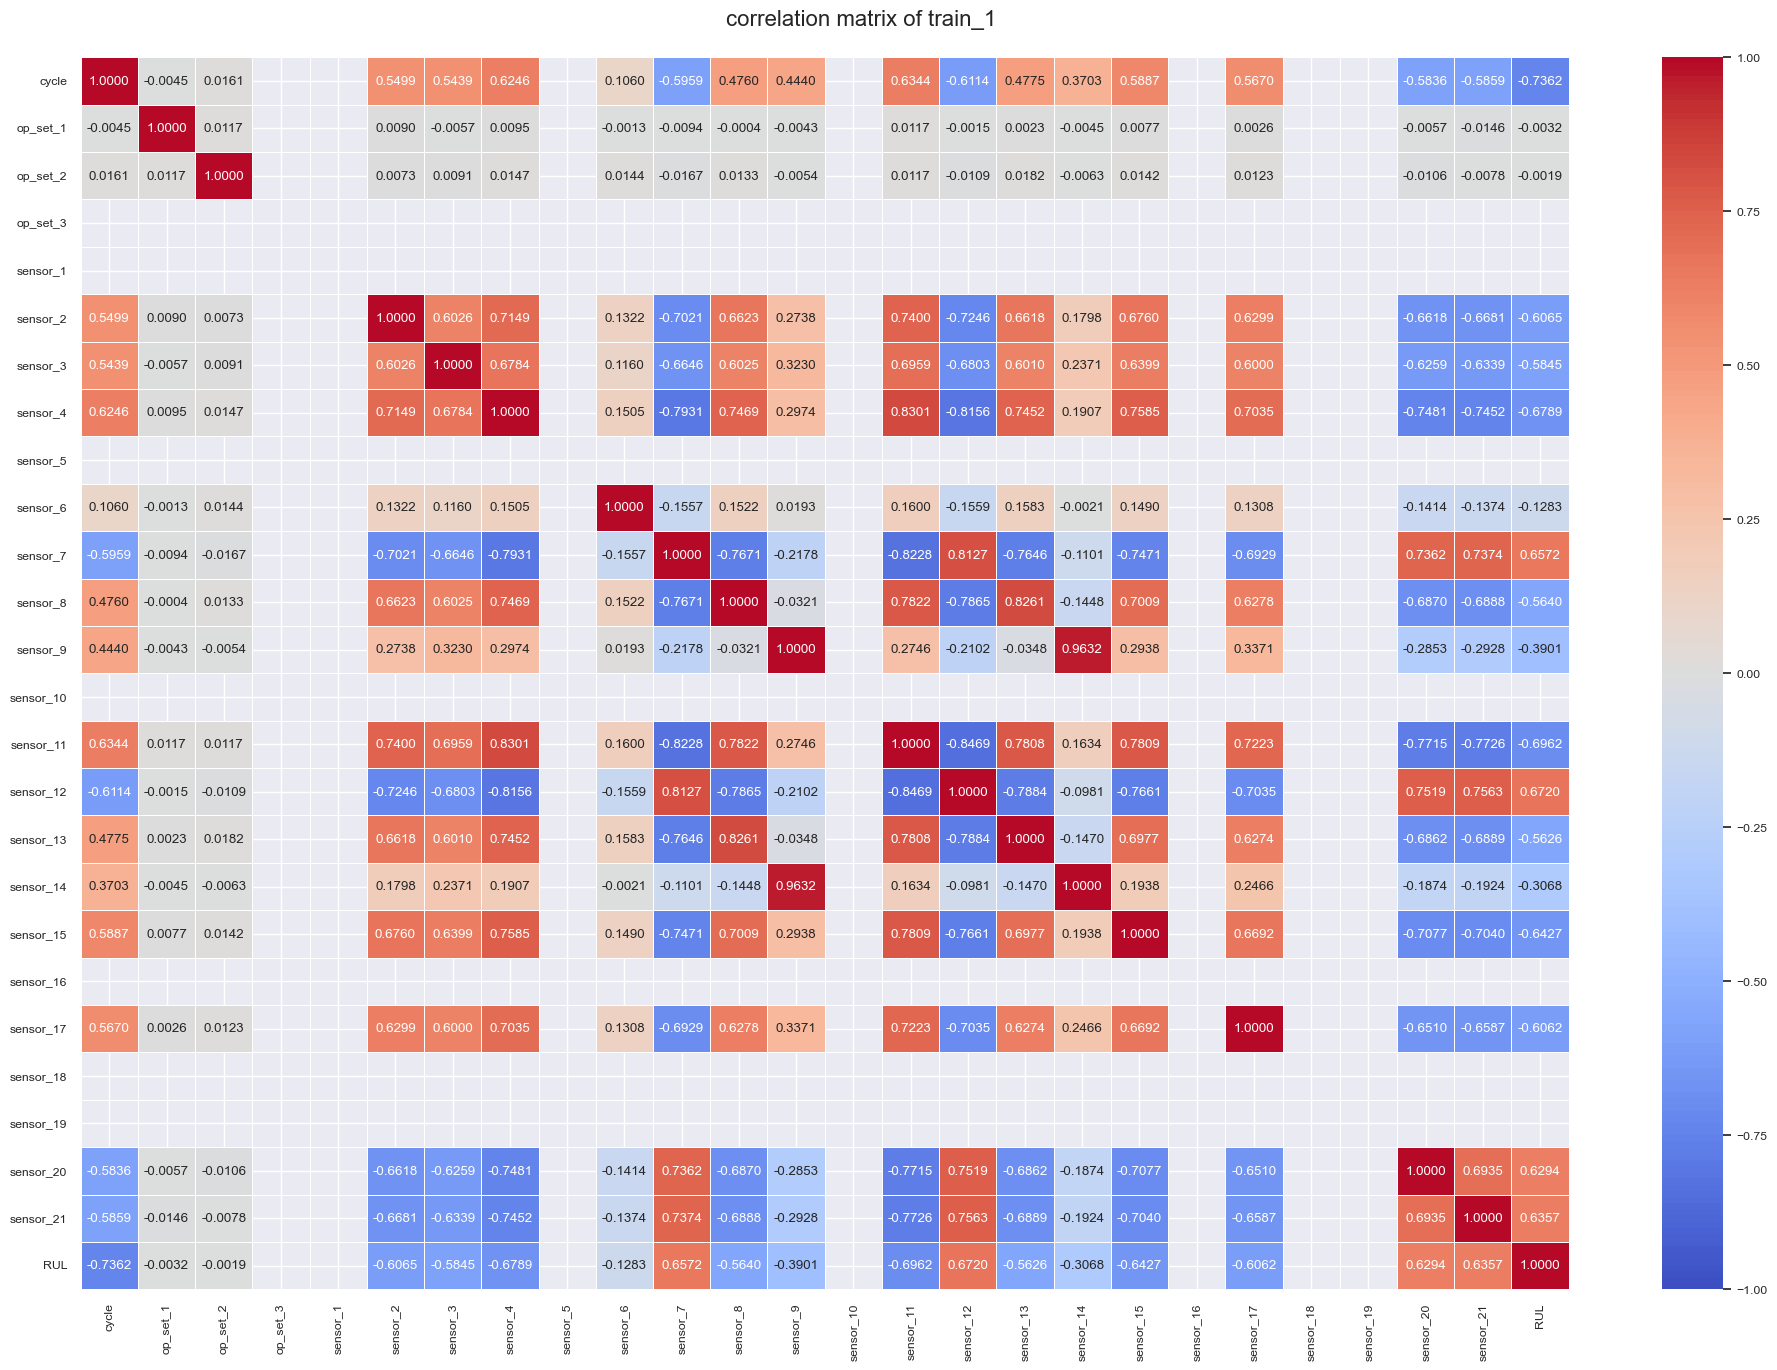

In [151]:
df_corr = rul_train_1.drop(columns=["engine_id"]).corr()

# correlation matrix
sns.set(font_scale = 0.8)
plt.figure(figsize = (24,16))
sns.heatmap(df_corr, annot=True, fmt=".4f",vmin=-1, vmax=1, linewidths=.5, cmap = sns.color_palette("coolwarm", 200))

plt.figtext(.45, 0.9,'correlation matrix of train_1', fontsize=16, ha='center')
plt.xticks(rotation=90)
plt.show()

In [152]:
rul_train_1.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189


In [153]:
rul_test_1.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,142
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,141
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,140


In [154]:
corr_del=["sensor_1", "sensor_5", "sensor_10", "sensor_16"]
rul_train_1.drop(columns = corr_del, inplace = True)
rul_test_1.drop(columns = corr_del, inplace = True)

In [155]:
print("Min RUL:", rul_train_1["RUL"].min())
print("Max RUL:", rul_train_1["RUL"].max())
print(rul_train_1["RUL"].describe())


Min RUL: 0
Max RUL: 361
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [ ]:
print(rul_train_1["RUL"].value_counts(normalize = True).sort_index())

RUL
0      0.004847
1      0.004847
2      0.004847
3      0.004847
4      0.004847
         ...   
357    0.000048
358    0.000048
359    0.000048
360    0.000048
361    0.000048
Name: proportion, Length: 362, dtype: float64


In [156]:
def rul_to_class_fd001(r):
    if r > 155:
        return 2 
    elif r > 51:
        return 1 
    else:
        return 0 

rul_train_1["label"] = rul_train_1["RUL"].apply(rul_to_class_fd001)
rul_test_1["label"] = rul_test_1["RUL"].apply(rul_to_class_fd001)


rul_train_1.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,...,sensor_13,sensor_14,sensor_15,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL,label
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,21.61,554.36,...,2388.02,8138.62,8.4195,392,2388,100.0,39.06,23.4190,191,2
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,21.61,553.75,...,2388.07,8131.49,8.4318,392,2388,100.0,39.00,23.4236,190,2
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,21.61,554.26,...,2388.03,8133.23,8.4178,390,2388,100.0,38.95,23.3442,189,2


In [157]:
rul_train_1.drop(['RUL'], axis = 1, inplace = True)
rul_test_1.drop(['RUL'], axis = 1, inplace = True)

In [158]:
np.save("./CMAPSSData/train_01.npy", rul_train_1)
np.save("./CMAPSSData/test_01.npy", rul_test_1)

In [131]:
import numpy as np
import builtins

for path in ["./CMAPSSData/train_01.npy", "./CMAPSSData/test_01.npy"]:
    arr = np.load(path, allow_pickle=True)
    print("\nPATH:", path)
    print("type:", type(arr))
    print("dtype:", getattr(arr, "dtype", None))
    print("shape:", getattr(arr, "shape", None))

    if isinstance(arr, np.ndarray) and arr.dtype == object:
        print("first element type:", type(arr.flat[0]))
        if arr.shape == ():
            obj = arr.item()
            print("scalar object type:", type(obj))
            if isinstance(obj, builtins.dict):
                print("dict keys:", list(obj.keys()))
            elif isinstance(obj, tuple):
                print("tuple length:", len(obj))
            elif isinstance(obj, list):
                print("list length:", len(obj))
      


PATH: ./CMAPSSData/train_01.npy
type: <class 'numpy.ndarray'>
dtype: object
shape: ()
first element type: <class 'NoneType'>
scalar object type: <class 'NoneType'>

PATH: ./CMAPSSData/test_01.npy
type: <class 'numpy.ndarray'>
dtype: object
shape: ()
first element type: <class 'NoneType'>
scalar object type: <class 'NoneType'>


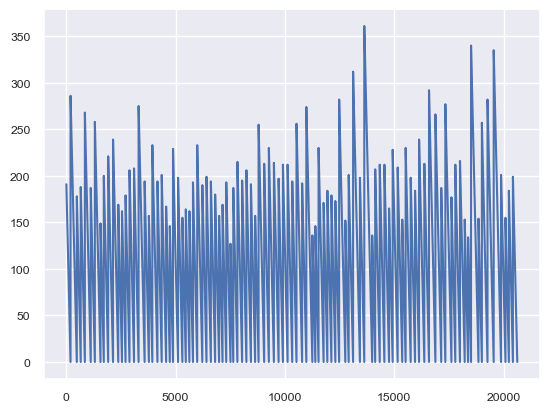

In [95]:
plt.plot(rul_train_1["RUL"])

In [25]:
rul_test_1.columns

Index(['engine_id', 'cycle', 'op_set_1', 'op_set_2', 'sensor_2', 'sensor_3',
       'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11',
       'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17',
       'sensor_20', 'sensor_21', 'label'],
      dtype='object')

CMAPSS FD002 dataset

In [5]:
rul_2_gt = pd.read_csv('./CMAPSSData/RUL_FD002.txt', header = None)
rul_2_gt.rename(columns={0: "RUL_2gt"}, inplace = True)

column_name_dict = { 0: "engine_id", 1: "cycle", 2: "op_set_1", 3: "op_set_2", 4: "op_set_3", 5:"sensor_1", 6: "sensor_2",
                   7: "sensor_3", 8: "sensor_4", 9: "sensor_5", 10: "sensor_6", 11: "sensor_7", 12: "sensor_8", 13: "sensor_9",
                  14: "sensor_10", 15: "sensor_11", 16: "sensor_12", 17: "sensor_13", 18: "sensor_14", 19: "sensor_15", 20: "sensor_16",
                  21: "sensor_17", 22: "sensor_18", 23: "sensor_19", 24: "sensor_20", 25: "sensor_21", 26: "sensor_22", 27: "sensor_23"}

test_2 = pd.read_csv('./CMAPSSData/test_FD002.txt', header = None, sep = ' ')
test_2.rename(columns = column_name_dict, inplace = True)

train_2 = pd.read_csv('./CMAPSSData/train_FD002.txt', header = None, sep = ' ')
train_2.rename(columns = column_name_dict, inplace = True)

In [8]:
train_2.drop(columns = ["sensor_22", "sensor_23"], inplace = True)
test_2.drop(columns = ["sensor_22", "sensor_23"], inplace = True)

In [9]:
rul_2 = pd.DataFrame(train_1.groupby('engine_id')['cycle'].max()).reset_index()
rul_2.columns = ['engine_id', 'max']

rul_train_2 = train_2.merge(rul_2, on = ['engine_id'], how = 'left')
rul_train_2['RUL'] = rul_train_2['max'] - rul_train_2['cycle']
rul_train_2.drop(['max'], axis = 1, inplace = True)

In [10]:
rul_train_2.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,148
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,147
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,146


In [12]:
rul_2_gt["engine_id"] = rul_2_gt.index + 1

max_2 = pd.DataFrame(test_2.groupby('engine_id')['cycle'].max()).reset_index()
max_2.columns = ['engine_id', 'max']
max_test_2 = test_2.merge(max_2, on=['engine_id'], how='left')
rul_test_2 = max_test_2.merge(rul_2_gt, on = ['engine_id'], how='left')

rul_test_2['RUL'] = rul_test_2['max'] - rul_test_2['cycle'] + rul_test_2["RUL_2gt"] 
rul_test_2.drop(['max', 'RUL_2gt'], axis = 1, inplace = True)

rul_train_2.groupby('engine_id')['cycle'].describe()

,count,mean,std,min,25%,50%,75%,max
engine_id,,,,,,,,
1,149.0,75.0,43.156691,1.0,38.00,75.0,112.00,149.0
2,269.0,135.0,77.797815,1.0,68.00,135.0,202.00,269.0
3,206.0,103.5,59.611241,1.0,52.25,103.5,154.75,206.0
4,235.0,118.0,67.982841,1.0,59.50,118.0,176.50,235.0
5,154.0,77.5,44.600075,1.0,39.25,77.5,115.75,154.0
...,...,...,...,...,...,...,...,...
256,163.0,82.0,47.198164,1.0,41.50,82.0,122.50,163.0
257,309.0,155.0,89.344838,1.0,78.00,155.0,232.00,309.0
258,143.0,72.0,41.424630,1.0,36.50,72.0,107.50,143.0


In [14]:
rul_train_2.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
engine_id,53759.0,131.082981,74.463862,1.0000,68.0000,131.0000,195.0000,260.0000
cycle,53759.0,109.154746,69.180569,1.0000,52.0000,104.0000,157.0000,378.0000
op_set_1,53759.0,23.998407,14.747376,0.0000,10.0046,25.0013,41.9980,42.0080
op_set_2,53759.0,0.572056,0.310016,0.0000,0.2507,0.7000,0.8400,0.8420
op_set_3,53759.0,94.046020,14.237735,60.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,53759.0,472.910207,26.389707,445.0000,445.0000,462.5400,491.1900,518.6700
sensor_2,53759.0,579.672399,37.289399,535.5300,549.5700,555.9800,607.3400,644.5200
sensor_3,53759.0,1419.971013,105.946341,1243.7300,1352.7600,1369.1800,1499.3700,1612.8800
sensor_4,53759.0,1205.442024,119.123428,1023.7700,1123.6550,1138.8900,1306.8500,1439.2300
sensor_5,53759.0,8.031986,3.613839,3.9100,3.9100,7.0500,10.5200,14.6200


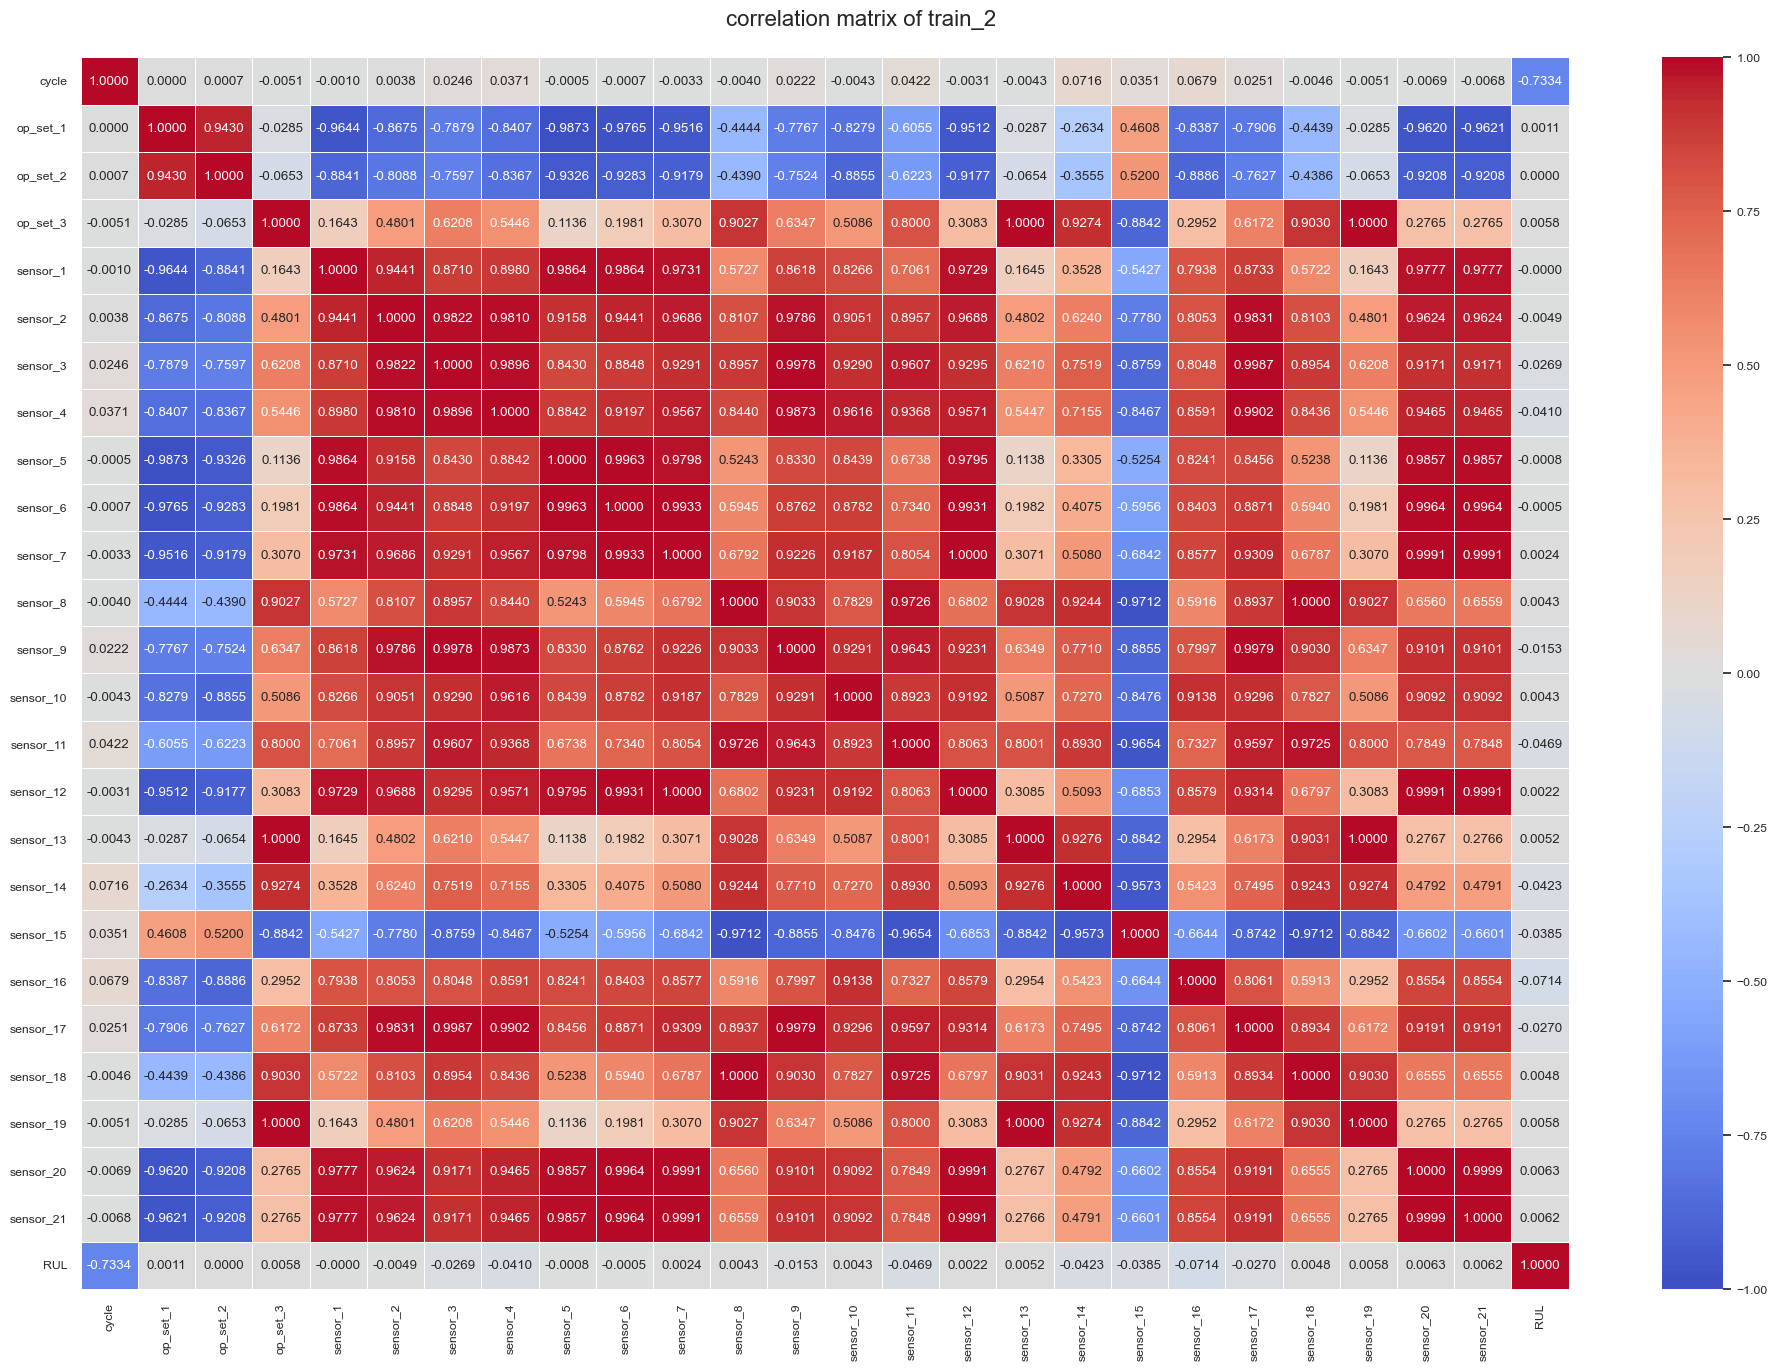

In [15]:
df_corr = rul_train_2.drop(columns=["engine_id"]).corr()

# correlation matrix
sns.set(font_scale = 0.8)
plt.figure(figsize = (24,16))
sns.heatmap(df_corr, annot = True, fmt = ".4f",vmin = -1, vmax = 1, linewidths = .5, cmap = sns.color_palette("coolwarm", 200))

plt.figtext(.45, 0.9,'correlation matrix of train_2', fontsize = 16, ha = 'center')
plt.xticks(rotation=90)
plt.show()

In [16]:
print("Min RUL:", rul_train_1["RUL"].min())
print("Max RUL:", rul_train_1["RUL"].max())
print(rul_train_1["RUL"].describe())

Min RUL: 0
Max RUL: 377
count    53759.000000
mean       108.154746
std         69.180569
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        377.000000
Name: RUL, dtype: float64


FD003 dataset

In [159]:
rul_3_gt = pd.read_csv('./CMAPSSData/RUL_FD003.txt', header = None)
rul_3_gt.rename(columns={0: "RUL_3gt"}, inplace = True)

column_name_dict = { 0: "engine_id", 1: "cycle", 2: "op_set_1", 3: "op_set_2", 4: "op_set_3", 5:"sensor_1", 6: "sensor_2",
                   7: "sensor_3", 8: "sensor_4", 9: "sensor_5", 10: "sensor_6", 11: "sensor_7", 12: "sensor_8", 13: "sensor_9",
                  14: "sensor_10", 15: "sensor_11", 16: "sensor_12", 17: "sensor_13", 18: "sensor_14", 19: "sensor_15", 20: "sensor_16",
                  21: "sensor_17", 22: "sensor_18", 23: "sensor_19", 24: "sensor_20", 25: "sensor_21", 26: "sensor_22", 27: "sensor_23"}

test_3 = pd.read_csv('./CMAPSSData/test_FD003.txt', header = None, sep = ' ')
test_3.rename(columns = column_name_dict, inplace = True)

train_3 = pd.read_csv('./CMAPSSData/train_FD003.txt', header = None, sep = ' ')
train_3.rename(columns = column_name_dict, inplace = True)

In [160]:
train_3.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_22,sensor_23
0,1,1,-0.0005,0.0004,100.0,518.67,642.36,1583.23,1396.84,14.62,...,8145.32,8.4246,0.03,391,2388,100.0,39.11,23.3537,NaN,NaN
1,1,2,0.0008,-0.0003,100.0,518.67,642.50,1584.69,1396.89,14.62,...,8152.85,8.4403,0.03,392,2388,100.0,38.99,23.4491,NaN,NaN
2,1,3,-0.0014,-0.0002,100.0,518.67,642.18,1582.35,1405.61,14.62,...,8150.17,8.3901,0.03,391,2388,100.0,38.85,23.3669,NaN,NaN


In [161]:
train_3.drop(columns = ["sensor_22", "sensor_23"], inplace = True)
test_3.drop(columns = ["sensor_22", "sensor_23"], inplace = True)

In [162]:
rul_3 = pd.DataFrame(train_3.groupby('engine_id')['cycle'].max()).reset_index()
rul_3.columns = ['engine_id', 'max']

rul_train_3 = train_3.merge(rul_3, on = ['engine_id'], how = 'left')
rul_train_3['RUL'] = rul_train_3['max'] - rul_train_3['cycle']
rul_train_3.drop(['max'], axis = 1, inplace = True)

rul_train_3.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0005,0.0004,100.0,518.67,642.36,1583.23,1396.84,14.62,...,2388.01,8145.32,8.4246,0.03,391,2388,100.0,39.11,23.3537,258
1,1,2,0.0008,-0.0003,100.0,518.67,642.50,1584.69,1396.89,14.62,...,2388.03,8152.85,8.4403,0.03,392,2388,100.0,38.99,23.4491,257
2,1,3,-0.0014,-0.0002,100.0,518.67,642.18,1582.35,1405.61,14.62,...,2388.00,8150.17,8.3901,0.03,391,2388,100.0,38.85,23.3669,256


In [163]:
rul_3_gt["engine_id"] = rul_3_gt.index + 1

max_3 = pd.DataFrame(test_3.groupby('engine_id')['cycle'].max()).reset_index()
max_3.columns = ['engine_id', 'max']
max_test_3 = test_3.merge(max_3, on = ['engine_id'], how = 'left')
rul_test_3 = max_test_3.merge(rul_3_gt, on = ['engine_id'], how = 'left')

rul_test_3['RUL'] = rul_test_3['max'] - rul_test_3['cycle'] + rul_test_3["RUL_3gt"] 
rul_test_3.drop(['max', 'RUL_3gt'], axis = 1, inplace = True)

rul_train_3.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
engine_id,24720.0,48.631877,2.934899e+01,1.0000,23.0000,47.0000,74.0000,100.0000
cycle,24720.0,139.077063,9.884668e+01,1.0000,62.0000,124.0000,191.0000,525.0000
op_set_1,24720.0,-0.000024,2.193545e-03,-0.0086,-0.0015,-0.0000,0.0015,0.0086
op_set_2,24720.0,0.000005,2.940429e-04,-0.0006,-0.0002,-0.0000,0.0003,0.0007
op_set_3,24720.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,24720.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,24720.0,642.457858,5.230311e-01,640.8400,642.0800,642.4000,642.7900,645.1100
sensor_3,24720.0,1588.079175,6.810418e+00,1564.3000,1583.2800,1587.5200,1592.4125,1615.3900
sensor_4,24720.0,1404.471212,9.773178e+00,1377.0600,1397.1875,1402.9100,1410.6000,1441.1600
sensor_5,24720.0,14.620000,3.552786e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [164]:
deleted_3 = ["op_set_3", "sensor_1","sensor_18", "sensor_19"]

rul_train_3.drop(columns = deleted_3, inplace = True)
rul_test_3.drop(columns = deleted_3, inplace = True)

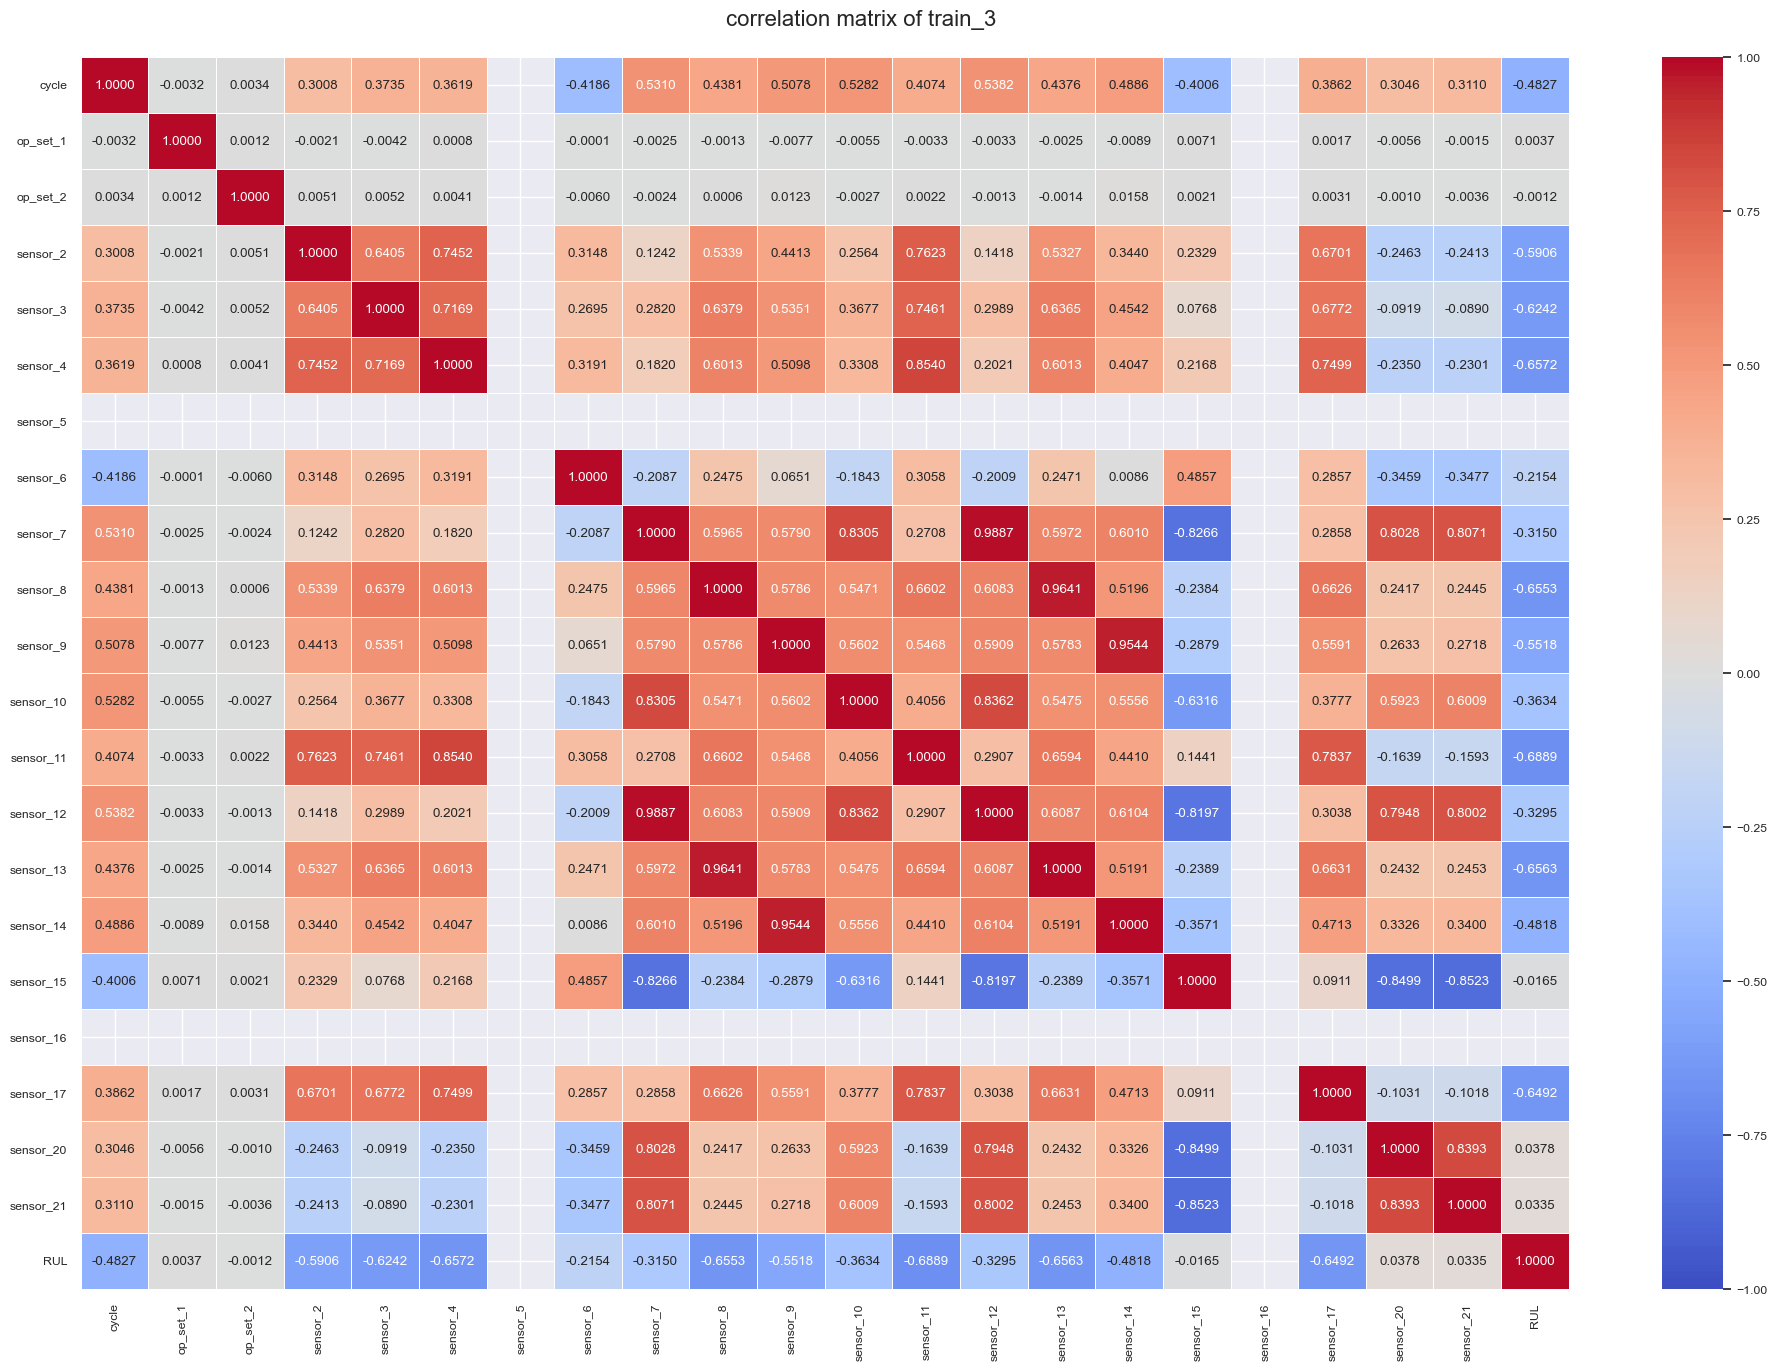

In [165]:
df_corr = rul_train_3.drop(columns=["engine_id"]).corr()

# correlation matrix
sns.set(font_scale = 0.8)
plt.figure(figsize = (24,16))
sns.heatmap(df_corr, annot = True, fmt = ".4f",vmin = -1, vmax = 1, linewidths = .5, cmap = sns.color_palette("coolwarm", 200))

plt.figtext(.45, 0.9,'correlation matrix of train_3', fontsize = 16, ha = 'center')
plt.xticks(rotation = 90)
plt.show()

In [166]:
print("Min RUL:", rul_train_3["RUL"].min())
print("Max RUL:", rul_train_3["RUL"].max())
print(rul_train_3["RUL"].describe())

Min RUL: 0
Max RUL: 524
count    24720.000000
mean       138.077063
std         98.846675
min          0.000000
25%         61.000000
50%        123.000000
75%        190.000000
max        524.000000
Name: RUL, dtype: float64


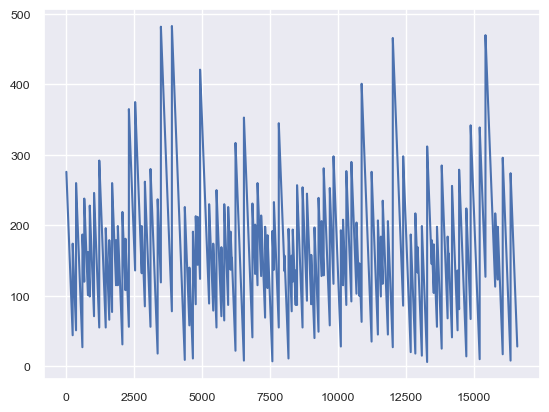

In [105]:
plt.plot(rul_test_3["RUL"])

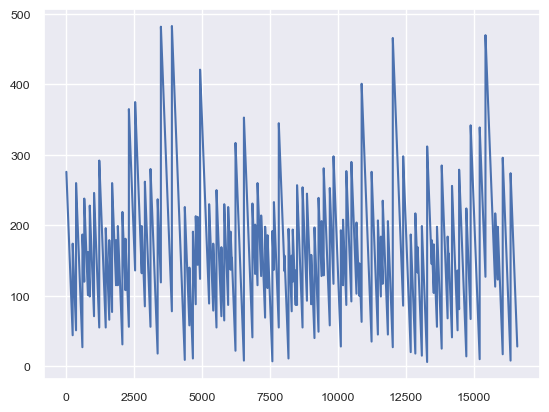

In [106]:
plt.plot(rul_test_3["RUL"])

In [167]:
def rul_to_class_fd003(rul):
    if rul > 190:
        return 2  
    elif rul > 61:
        return 1  
    else:
        return 0 

rul_train_3["label"] = rul_train_3["RUL"].apply(rul_to_class_fd003)
rul_test_3["label"] = rul_test_3["RUL"].apply(rul_to_class_fd003)

rul_test_3.drop(columns = ["RUL"], axis = 1, inplace = True)
rul_train_3.drop(columns = ["RUL"], axis = 1, inplace = True)


rul_train_3.head(3)

,engine_id,cycle,op_set_1,op_set_2,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_20,sensor_21,label
0,1,1,-0.0005,0.0004,642.36,1583.23,1396.84,14.62,21.61,553.97,...,47.30,522.31,2388.01,8145.32,8.4246,0.03,391,39.11,23.3537,2
1,1,2,0.0008,-0.0003,642.50,1584.69,1396.89,14.62,21.61,554.55,...,47.23,522.42,2388.03,8152.85,8.4403,0.03,392,38.99,23.4491,2
2,1,3,-0.0014,-0.0002,642.18,1582.35,1405.61,14.62,21.61,554.43,...,47.22,522.03,2388.00,8150.17,8.3901,0.03,391,38.85,23.3669,2


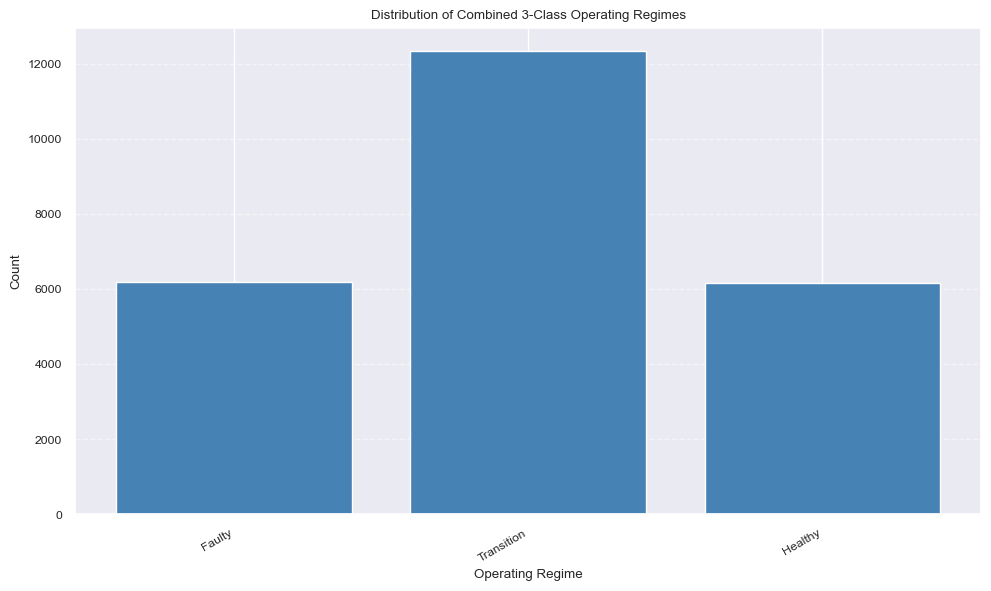

In [113]:
labels, counts = np.unique(rul_train_3["label"], return_counts = True)
ordered_labels = list(range(3))
ordered_counts = [
counts[labels.tolist().index(lbl)] if lbl in labels else 0
for lbl in ordered_labels
]

class_names = {
0: "Faulty",
1: "Transition",
2: "Healthy",
}

wrapped_labels = [textwrap.fill(class_names[i], width = 12) for i in ordered_labels]

plt.figure(figsize = (10, 6))
plt.bar(wrapped_labels, ordered_counts, color = "steelblue")
plt.title("Distribution of Combined 3-Class Operating Regimes")
plt.xlabel("Operating Regime")
plt.ylabel("Count")
plt.xticks(rotation = 30, ha = "right")  
plt.grid(axis = 'y', linestyle='--', alpha = 0.5)
plt.tight_layout()
plt.savefig("./figures/CMAPSS_03_train_labels.png")

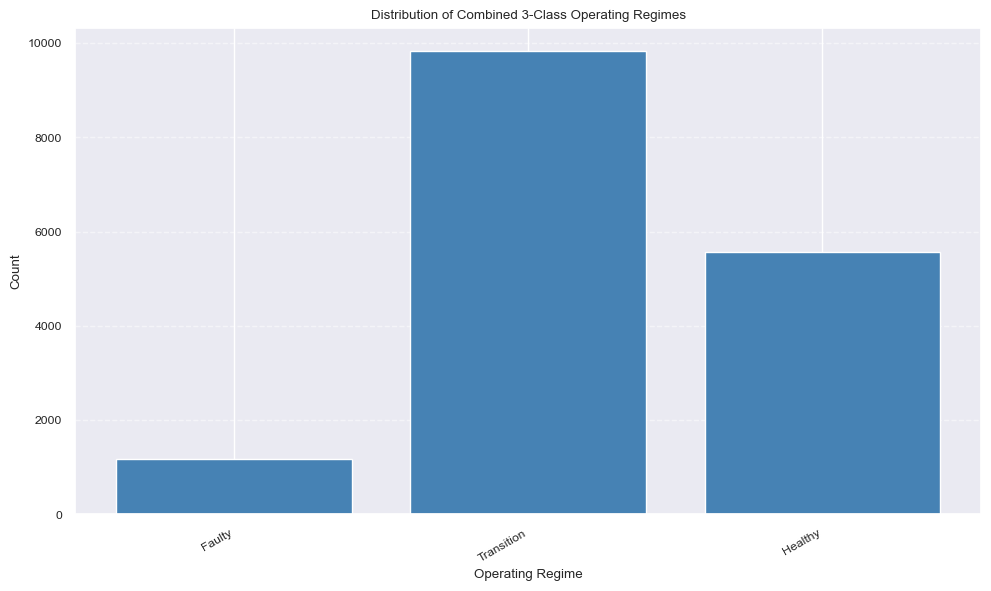

In [114]:
labels, counts = np.unique(rul_test_3["label"], return_counts = True)
ordered_labels = list(range(3))
ordered_counts = [
counts[labels.tolist().index(lbl)] if lbl in labels else 0
for lbl in ordered_labels
]

class_names = {
0: "Faulty",
1: "Transition",
2: "Healthy",
}

wrapped_labels = [textwrap.fill(class_names[i], width = 12) for i in ordered_labels]

plt.figure(figsize = (10, 6))
plt.bar(wrapped_labels, ordered_counts, color = "steelblue")
plt.title("Distribution of Combined 3-Class Operating Regimes")
plt.xlabel("Operating Regime")
plt.ylabel("Count")
plt.xticks(rotation = 30, ha = "right")  
plt.grid(axis = 'y', linestyle='--', alpha = 0.5)
plt.tight_layout()
plt.savefig("./figures/CMAPSS_03_test_labels.png")

In [168]:
np.save("./CMAPSSData/train_03.npy", rul_train_3)
np.save("./CMAPSSData/test_03.npy", rul_test_3)

FD004 dataset

In [26]:
rul_4_gt = pd.read_csv('./CMAPSSData/RUL_FD004.txt', header = None)
rul_4_gt.rename(columns = {0: "RUL_4gt"}, inplace = True)

column_name_dict = { 0: "engine_id", 1: "cycle", 2: "op_set_1", 3: "op_set_2", 4: "op_set_3", 5:"sensor_1", 6: "sensor_2",
                   7: "sensor_3", 8: "sensor_4", 9: "sensor_5", 10: "sensor_6", 11: "sensor_7", 12: "sensor_8", 13: "sensor_9",
                  14: "sensor_10", 15: "sensor_11", 16: "sensor_12", 17: "sensor_13", 18: "sensor_14", 19: "sensor_15", 20: "sensor_16",
                  21: "sensor_17", 22: "sensor_18", 23: "sensor_19", 24: "sensor_20", 25: "sensor_21", 26: "sensor_22", 27: "sensor_23"}

test_4 = pd.read_csv('./CMAPSSData/test_FD004.txt', header = None, sep = ' ')
test_4.rename(columns = column_name_dict, inplace = True)

train_4 = pd.read_csv('./CMAPSSData/train_FD004.txt', header = None, sep = ' ')
train_4.rename(columns = column_name_dict, inplace = True)

In [27]:
train_4.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_22,sensor_23
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,8074.83,9.3335,0.02,330,2212,100.0,10.62,6.3670,NaN,NaN
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,8046.13,9.1913,0.02,361,2324,100.0,24.37,14.6552,NaN,NaN
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,8066.62,9.4007,0.02,329,2212,100.0,10.48,6.4213,NaN,NaN


In [29]:
train_4.drop(columns = ["sensor_22", "sensor_23"], inplace = True)
test_4.drop(columns = ["sensor_22", "sensor_23"], inplace = True)


rul_4 = pd.DataFrame(train_4.groupby('engine_id')['cycle'].max()).reset_index()
rul_4.columns = ['engine_id', 'max']

rul_train_4 = train_4.merge(rul_4, on = ['engine_id'], how = 'left')
rul_train_4['RUL'] = rul_train_4['max'] - rul_train_4['cycle']
rul_train_4.drop(['max'], axis = 1, inplace = True)

rul_train_4.head(3)

,engine_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,2387.99,8074.83,9.3335,0.02,330,2212,100.0,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,2387.73,8046.13,9.1913,0.02,361,2324,100.0,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,2387.97,8066.62,9.4007,0.02,329,2212,100.0,10.48,6.4213,318


In [32]:
rul_4_gt["engine_id"] = rul_4_gt.index + 1

max_4 = pd.DataFrame(test_4.groupby('engine_id')['cycle'].max()).reset_index()
max_4.columns = ['engine_id', 'max']
max_test_4 = test_4.merge(max_4, on = ['engine_id'], how = 'left')
rul_test_4 = max_test_4.merge(rul_4_gt, on = ['engine_id'], how = 'left')

rul_test_4['RUL'] = rul_test_4['max'] - rul_test_4['cycle'] + rul_test_4["RUL_4gt"] 
rul_test_4.drop(['max', 'RUL_4gt'], axis = 1, inplace = True)

rul_train_4.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
engine_id,61249.0,124.325181,71.995350,1.0000,60.0000,126.0000,185.0000,249.0000
cycle,61249.0,134.311417,89.783389,1.0000,62.0000,123.0000,191.0000,543.0000
op_set_1,61249.0,23.999823,14.780722,0.0000,10.0046,25.0014,41.9981,42.0080
op_set_2,61249.0,0.571347,0.310703,0.0000,0.2507,0.7000,0.8400,0.8420
op_set_3,61249.0,94.031576,14.251954,60.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,61249.0,472.882435,26.436832,445.0000,445.0000,462.5400,491.1900,518.6700
sensor_2,61249.0,579.420056,37.342647,535.4800,549.3300,555.7400,607.0700,644.4200
sensor_3,61249.0,1417.896600,106.167598,1242.6700,1350.5500,1367.6800,1497.4200,1613.0000
sensor_4,61249.0,1201.915359,119.327591,1024.4200,1119.4900,1136.9200,1302.6200,1440.7700
sensor_5,61249.0,8.031626,3.622872,3.9100,3.9100,7.0500,10.5200,14.6200


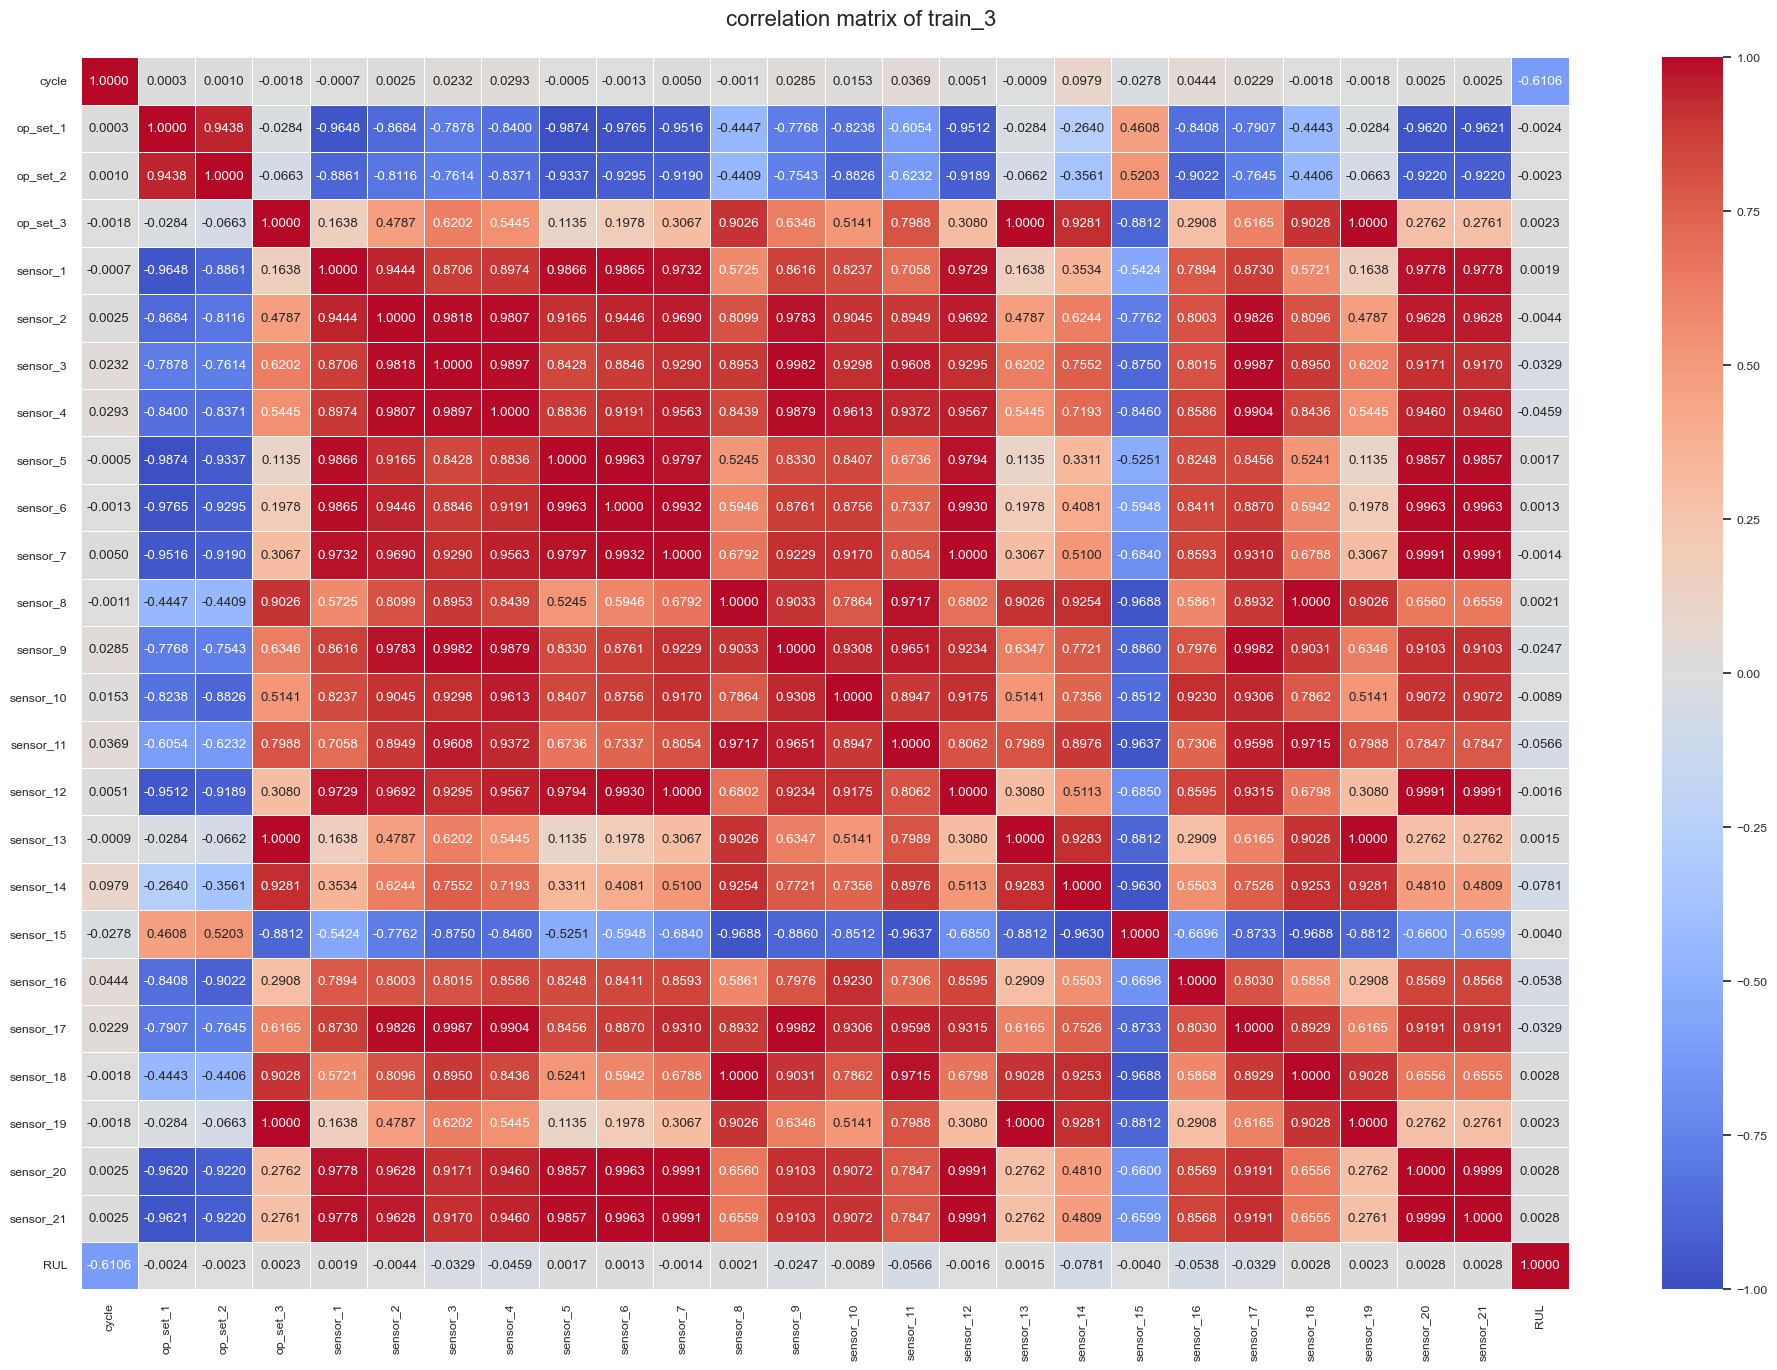

In [33]:
df_corr = rul_train_4.drop(columns=["engine_id"]).corr()

# correlation matrix
sns.set(font_scale = 0.8)
plt.figure(figsize = (24,16))
sns.heatmap(df_corr, annot = True, fmt = ".4f",vmin = -1, vmax = 1, linewidths = .5, cmap = sns.color_palette("coolwarm", 200))

plt.figtext(.45, 0.9,'correlation matrix of train_3', fontsize = 16, ha = 'center')
plt.xticks(rotation = 90)
plt.show()

In [34]:
print("Min RUL:", rul_train_4["RUL"].min())
print("Max RUL:", rul_train_4["RUL"].max())
print(rul_train_4["RUL"].describe())

Min RUL: 0
Max RUL: 542
count    61249.000000
mean       133.311417
std         89.783389
min          0.000000
25%         61.000000
50%        122.000000
75%        190.000000
max        542.000000
Name: RUL, dtype: float64


In [ ]:
DATA_DIR = Path("./CMAPSSData")

CMAPSS_COLUMNS = (
    ["unit", "cycle", "op_set_1", "op_set_2", "op_set_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def make_cmapss_npy(fd_id, data_dir=DATA_DIR):
    """
    Creates:
      CMAPSSData/train_02.npy, test_02.npy
      CMAPSSData/train_03.npy, test_03.npy
      CMAPSSData/train_04.npy, test_04.npy

    Output column order:
      unit, cycle, op_set_1, op_set_2, op_set_3, sensor_1...sensor_21, RUL
    """
    fd = f"{fd_id:03d}"
    short = f"{fd_id:02d}"

    train_path = data_dir / f"train_FD{fd}.txt"
    test_path = data_dir / f"test_FD{fd}.txt"
    rul_path = data_dir / f"RUL_FD{fd}.txt"

    train = pd.read_csv(
        train_path,
        sep=r"\s+",
        header=None,
        names=CMAPSS_COLUMNS
    )

    test = pd.read_csv(
        test_path,
        sep=r"\s+",
        header=None,
        names=CMAPSS_COLUMNS
    )

    final_rul = pd.read_csv(
        rul_path,
        sep=r"\s+",
        header=None,
        names=["final_RUL"]
    )

    final_rul["unit"] = np.arange(1, len(final_rul) + 1)

    # Training RUL: train trajectories run until failure.
    train = train.sort_values(["unit", "cycle"]).reset_index(drop=True)
    train["max_cycle"] = train.groupby("unit")["cycle"].transform("max")
    train["RUL"] = train["max_cycle"] - train["cycle"]
    train = train.drop(columns=["max_cycle"])

    # Test RUL: test trajectories are truncated; RUL file gives RUL after final observed cycle.
    test = test.sort_values(["unit", "cycle"]).reset_index(drop=True)
    test["max_cycle"] = test.groupby("unit")["cycle"].transform("max")
    test = test.merge(final_rul, on="unit", how="left")
    test["RUL"] = test["max_cycle"] - test["cycle"] + test["final_RUL"]
    test = test.drop(columns=["max_cycle", "final_RUL"])

    expected_cols = CMAPSS_COLUMNS + ["RUL"]
    train = train[expected_cols]
    test = test[expected_cols]

    train_arr = train.to_numpy(dtype=np.float32)
    test_arr = test.to_numpy(dtype=np.float32)

    train_out = data_dir / f"train_{short}.npy"
    test_out = data_dir / f"test_{short}.npy"

    np.save(train_out, train_arr)
    np.save(test_out, test_arr)

    print(f"FD{fd}")
    print(f"  saved: {train_out} | shape: {train_arr.shape}")
    print(f"  saved: {test_out}  | shape: {test_arr.shape}")
    print(f"  train units: {train['unit'].nunique()} | test units: {test['unit'].nunique()}")
    print(f"  train RUL range: {train['RUL'].min()} to {train['RUL'].max()}")
    print(f"  test RUL range:  {test['RUL'].min()} to {test['RUL'].max()}")
    print()

for fd_id in [2, 3, 4]:
    make_cmapss_npy(fd_id)

In [ ]:
def plot_rul_vs_time(df):

    plt.figure(figsize=(12, 6))
    for eid, group in df.groupby("engine_id"):
        plt.plot(group["cycle"], group["RUL"], alpha=0.6, linewidth=1)

    plt.title("RUL vs Time for Each Engine")
    plt.xlabel("Cycle")
    plt.ylabel("Remaining Useful Life (RUL)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


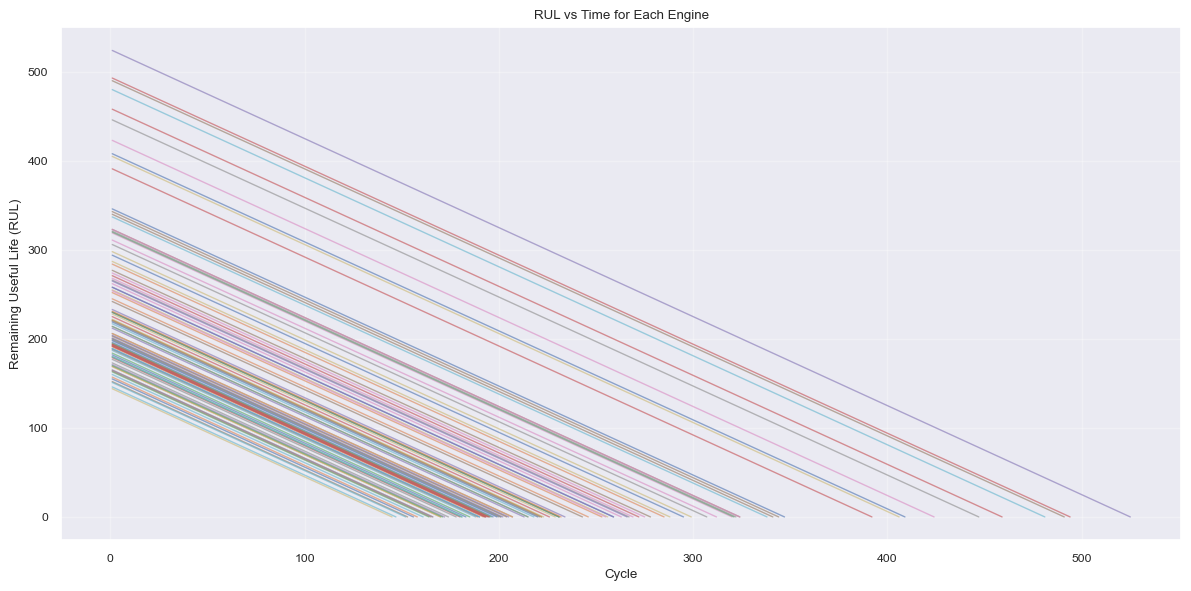

In [60]:
plot_rul_vs_time(rul_train_3)

In [61]:
def plot_sensor_drifts(df, sensors=None):
    """
    Plots sensor drift over time for each sensor.
    sensors: list of sensor column names. If None, auto-detect 's*'.
    """
    if sensors is None:
        sensors = [c for c in df.columns if c.startswith("s")]

    n = len(sensors)
    fig, axes = plt.subplots(n, 1, figsize=(12, 3*n), sharex=True)

    for ax, s in zip(axes, sensors):
        for eid, group in df.groupby("engine_id"):
            ax.plot(group["cycle"], group[s], alpha=0.3)
        ax.set_title(f"Sensor Drift: {s}")
        ax.grid(True, alpha=0.3)

    plt.xlabel("Cycle")
    plt.tight_layout()
    plt.show()


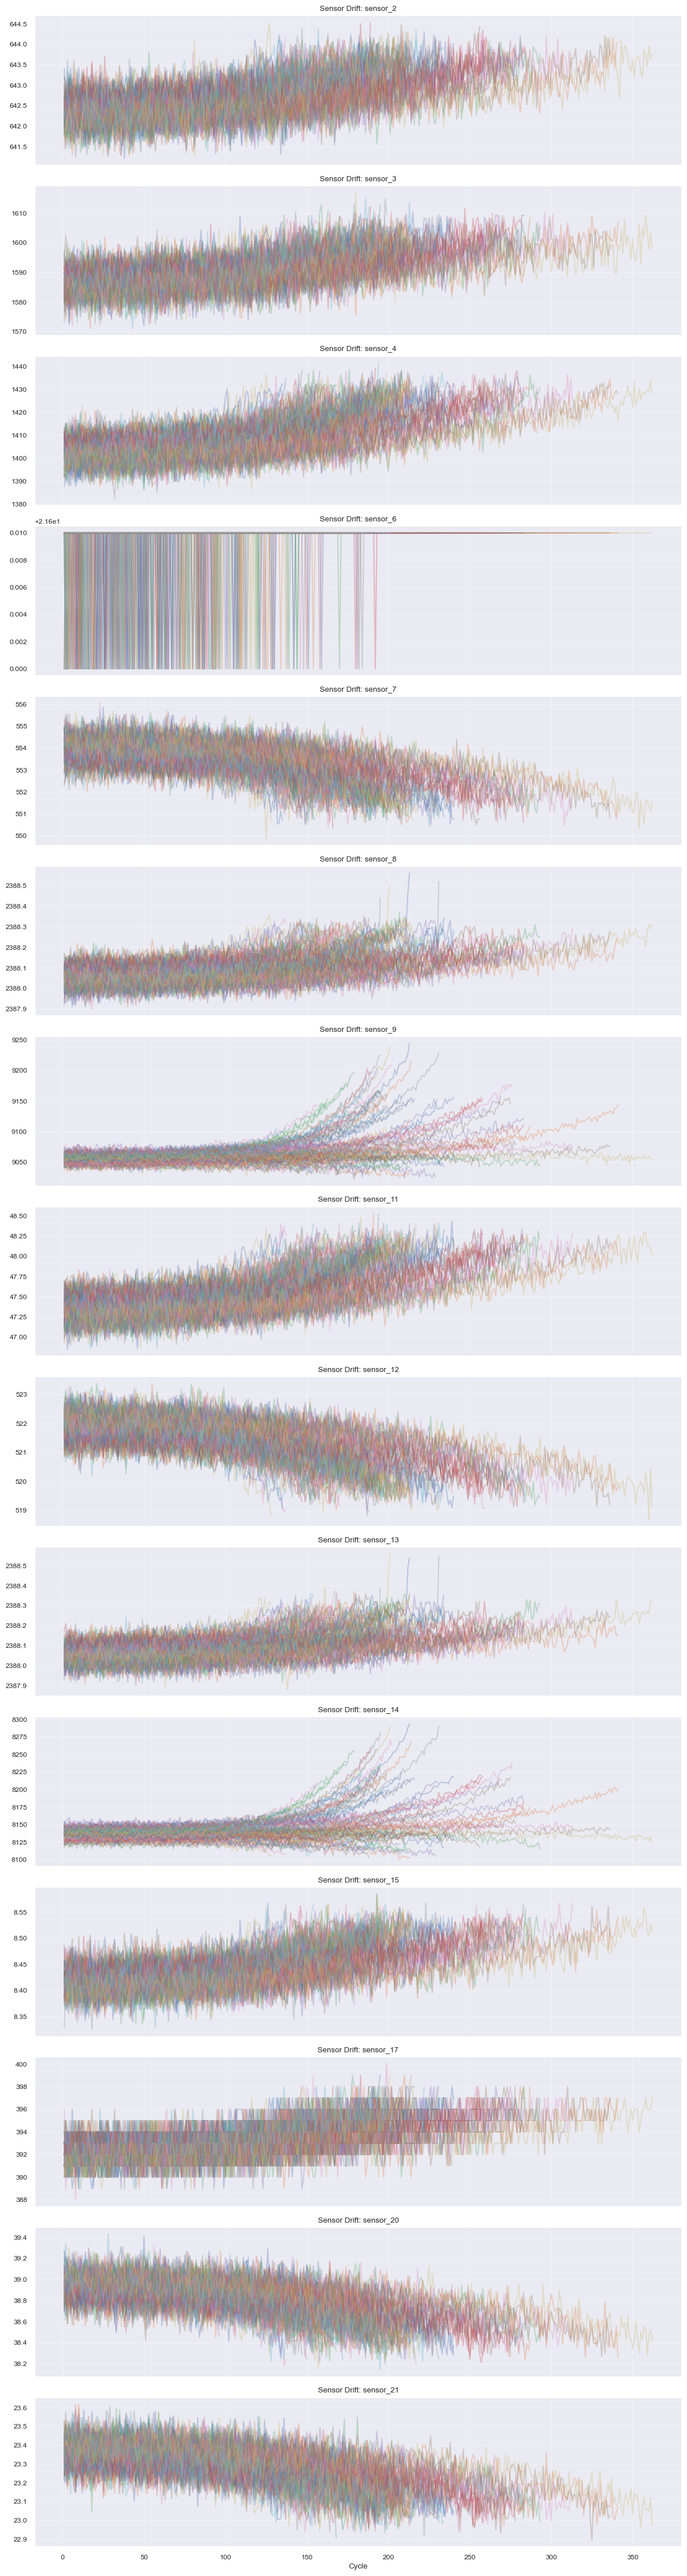

In [62]:
plot_sensor_drifts(rul_train_1)

In [ ]:
def plot_fd_comparison(fd_dict):
    """
    fd_dict: {"FD001": df1, "FD002": df2, "FD003": df3, "FD004": df4}
    Creates a dashboard comparing dataset sizes and engine counts.
    """
    stats = []
    for name, df in fd_dict.items():
        stats.append({
            "Dataset": name,
            "Num Engines": df["engine_id"].nunique(),
            "Num Cycles": len(df),
            "Num Sensors": len([c for c in df.columns if c.startswith("s")])
        })

    stats = pd.DataFrame(stats)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.barplot(data = stats, x = "Dataset", y = "Num Engines", ax=axes[0])
    axes[0].set_title("Number of Engines")

    sns.barplot(data=stats, x="Dataset", y="Num Cycles", ax=axes[1])
    axes[1].set_title("Total Cycles")

    sns.barplot(data=stats, x="Dataset", y="Num Sensors", ax=axes[2])
    axes[2].set_title("Number of Sensors")

    plt.tight_layout()
    plt.show()


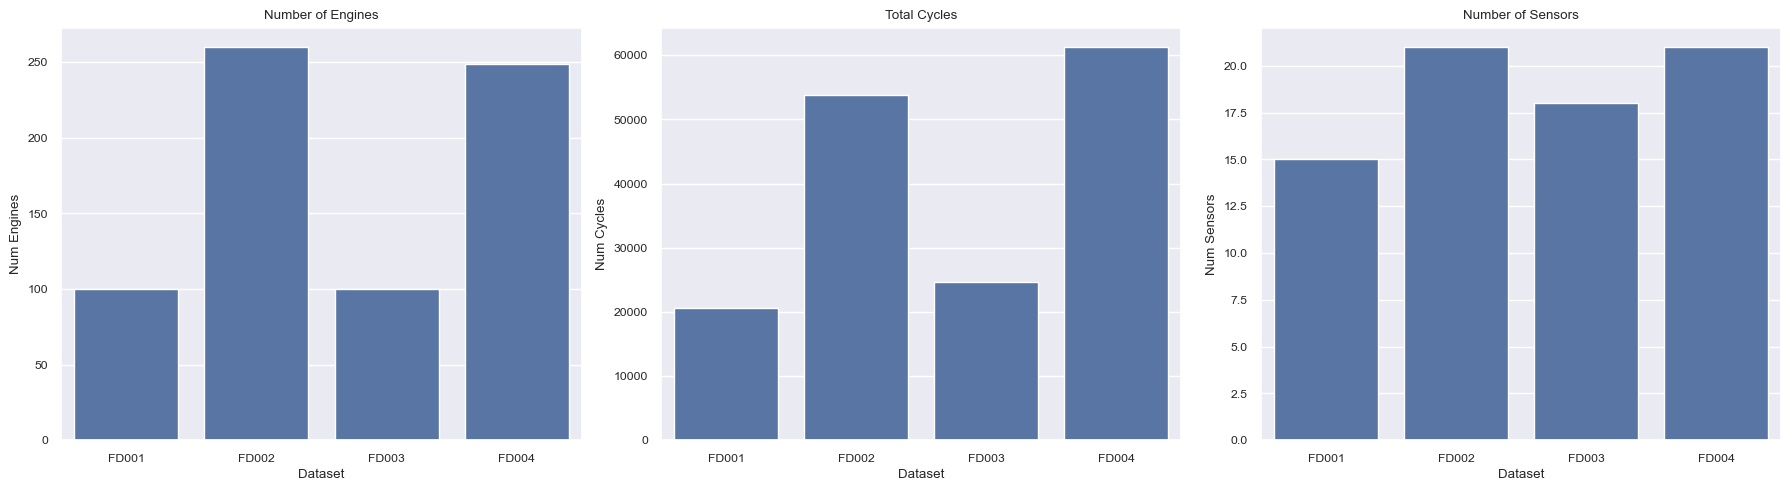

In [64]:
dict = {"FD001": rul_train_1, "FD002": rul_train_2, "FD003": rul_train_3, "FD004": rul_train_4}
plot_fd_comparison(dict)